# Student Performance Analysis Using Python, Pandas and NumPy


#### Importing Libaries 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Loading Dataset

In [4]:
df = pd.read_csv(r"C:\Users\KOMAL\Downloads\student_records_marks_attendance.csv")

In [5]:
df.head(25)

,Student_ID,Student_Name,Gender,Class,Section,Date_of_Birth,Maths_Marks,Science_Marks,English_Marks,Social_Studies_Marks,Computer_Marks,Attendance_Percentage
0,STU1001,Aarav Sharma,Male,6,A,2014-04-12,78,85,82,91,88,94
1,STU1002,Priya Verma,Female,6,A,2014-09-23,91,89,95,93,90,98
2,STU1003,Rohan Gupta,Male,6,A,2015-01-05,67,72,70,75,68,86
3,STU1004,Ananya Singh,Female,6,A,2014-07-17,88,92,90,87,94,96
4,STU1005,Kabir Mehta,Male,7,B,2013-11-29,74,69,77,81,73,89
5,STU1006,Sneha Patel,Female,7,B,2014-03-08,95,93,97,91,96,99
6,STU1007,Ishaan Kumar,Male,7,B,2013-06-14,62,66,71,64,69,78
7,STU1008,Neha Yadav,Female,7,B,2013-12-02,83,86,80,88,84,92
8,STU1009,Aditya Joshi,Male,8,A,2012-02-21,79,75,82,77,81,90
9,STU1010,Kavya Nair,Female,8,A,2012-08-10,92,96,94,89,95,97


#### Checking Null Values

In [6]:
df.isnull().sum()

Student_ID               0
Student_Name             0
Gender                   0
Class                    0
Section                  0
Date_of_Birth            0
Maths_Marks              0
Science_Marks            0
English_Marks            0
Social_Studies_Marks     0
Computer_Marks           0
Attendance_Percentage    0
dtype: int64

#### Calculating Total Marks And Average Marks 

In [7]:
Subjects =['Maths_Marks','Science_Marks','English_Marks','Social_Studies_Marks','Computer_Marks']

df["Total_Marks"] = np.sum(df[Subjects].to_numpy(), axis=1)

df["Average_Marks"] = np.mean(df[Subjects].to_numpy(), axis=1)

print(df[["Student_ID", "Student_Name", "Total_Marks", "Average_Marks"]])

   Student_ID    Student_Name  Total_Marks  Average_Marks
0     STU1001    Aarav Sharma          424           84.8
1     STU1002     Priya Verma          458           91.6
2     STU1003     Rohan Gupta          352           70.4
3     STU1004    Ananya Singh          451           90.2
4     STU1005     Kabir Mehta          374           74.8
5     STU1006     Sneha Patel          472           94.4
6     STU1007    Ishaan Kumar          332           66.4
7     STU1008      Neha Yadav          421           84.2
8     STU1009    Aditya Joshi          394           78.8
9     STU1010      Kavya Nair          466           93.2
10    STU1011      Vihaan Das          319           63.8
11    STU1012       Meera Rao          437           87.4
12    STU1013  Arjun Malhotra          379           75.8
13    STU1014     Diya Kapoor          478           95.6
14    STU1015    Reyansh Jain          347           69.4
15    STU1016      Ira Chawla          451           90.2
16    STU1017 

#### Bar Chart Showing Total Marks Of Each Student

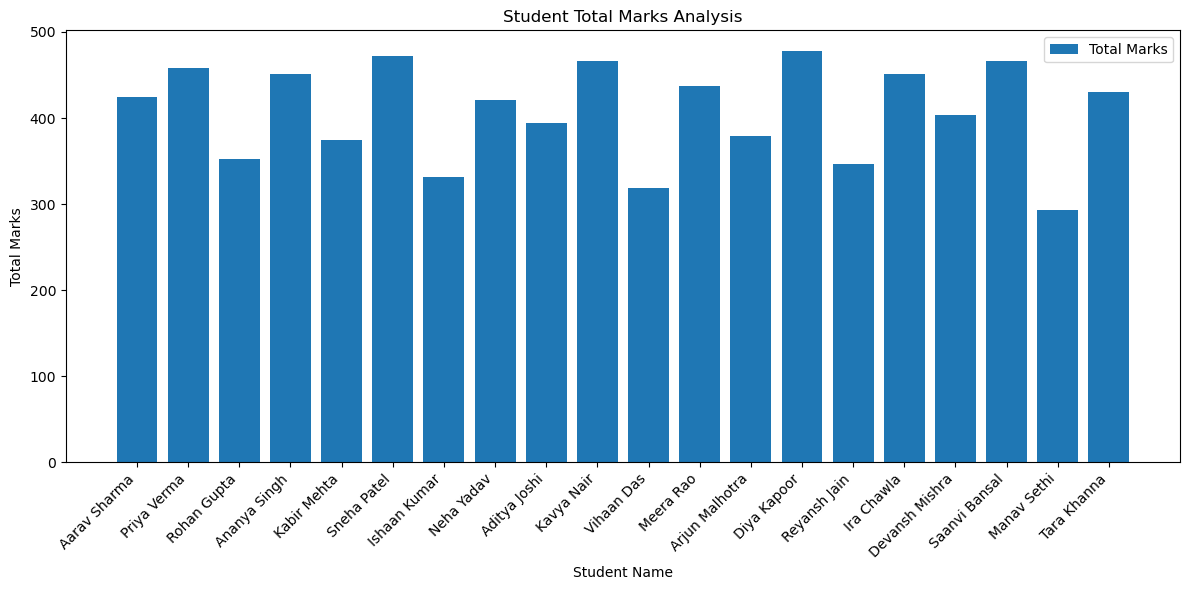

In [8]:
plt.figure(figsize=(12, 6))

plt.bar(df["Student_Name"], df["Total_Marks"],
        label="Total Marks")

plt.title("Student Total Marks Analysis")
plt.xlabel("Student Name")
plt.ylabel("Total Marks")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

#### Calculating Grades

In [9]:

subjects = ["Maths", "Science", "English", "Python", "Database"]

def calculate_grade(average):
    if average >= 90:
        return "A"
    elif average >= 75:
        return "B"
    elif average >= 60:
        return "C"
    elif average >= 35:
        return "D"
    else:
        return "F"

df["Grade"] = df["Average_Marks"].apply(calculate_grade)
print(df[["Student_ID", "Student_Name", "Total_Marks", "Average_Marks","Grade"]].head())

  Student_ID  Student_Name  Total_Marks  Average_Marks Grade
0    STU1001  Aarav Sharma          424           84.8     B
1    STU1002   Priya Verma          458           91.6     A
2    STU1003   Rohan Gupta          352           70.4     C
3    STU1004  Ananya Singh          451           90.2     A
4    STU1005   Kabir Mehta          374           74.8     C


#### 

#### Student Grade Distribution

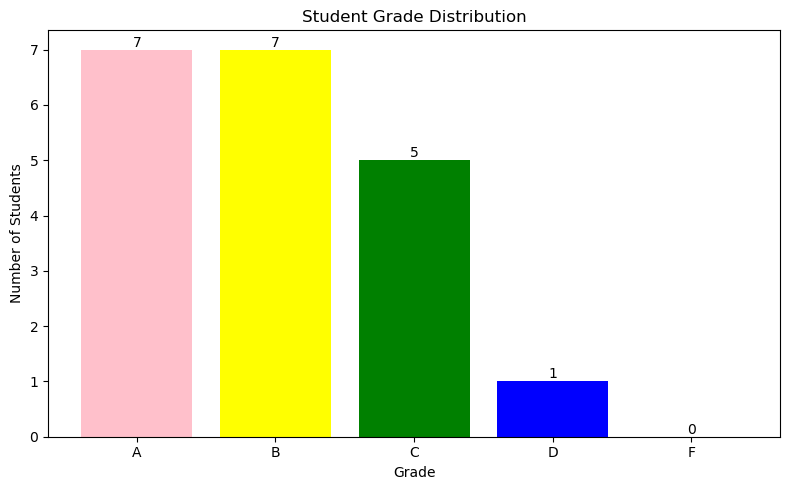

In [10]:
grade_counts = df["Grade"].value_counts().reindex(
    ["A", "B", "C", "D", "F"], fill_value=0
)

# Create the chart
plt.figure(figsize=(8, 5))
bars = plt.bar(grade_counts.index, grade_counts.values ,color=['Pink','yellow','green','blue'])

plt.title("Student Grade Distribution")
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.bar_label(bars)
plt.tight_layout()
plt.show()

#### Function to check pass or fail

In [11]:

def calculate_result(marks):
    if all(mark >= 35 for mark in marks):
        return "Pass"
    else:
        return "Fail"


# Assign pass/fail result
df["Result"] = df[Subjects].apply(
    lambda row: calculate_result(row.tolist()), axis=1)

print(df[["Student_ID", "Student_Name", "Total_Marks", "Average_Marks","Grade","Result"]].head())


  Student_ID  Student_Name  Total_Marks  Average_Marks Grade Result
0    STU1001  Aarav Sharma          424           84.8     B   Pass
1    STU1002   Priya Verma          458           91.6     A   Pass
2    STU1003   Rohan Gupta          352           70.4     C   Pass
3    STU1004  Ananya Singh          451           90.2     A   Pass
4    STU1005   Kabir Mehta          374           74.8     C   Pass


#### Result 

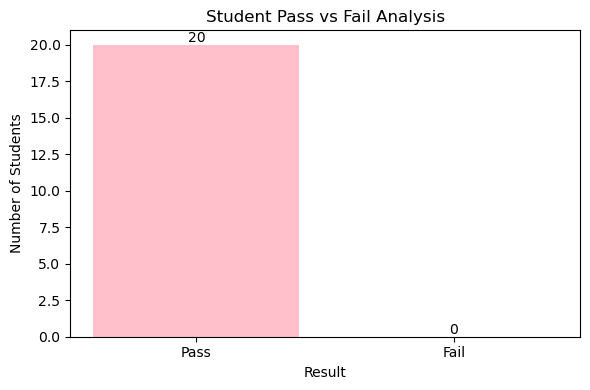

In [12]:
result_counts = df["Result"].value_counts().reindex(
    ["Pass", "Fail"], fill_value=0
)

plt.figure(figsize=(6, 4))
bars = plt.bar(result_counts.index, result_counts.values, color='pink')

plt.title("Student Pass vs Fail Analysis")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.bar_label(bars)

plt.tight_layout()
plt.show()

#### Calculating Highest Average, Lowest Average And Overall Class Average

In [13]:
highest = df["Average_Marks"].max()
lowest = df["Average_Marks"].min()
overall_average = df["Average_Marks"].mean()

print("Highest Average:", highest)
print("Lowest Average:", lowest)
print("Overall Class Average:", round(overall_average, 2))

Highest Average: 95.6
Lowest Average: 58.6
Overall Class Average: 81.48


#### Bar Chart Showing Overall Student Performance

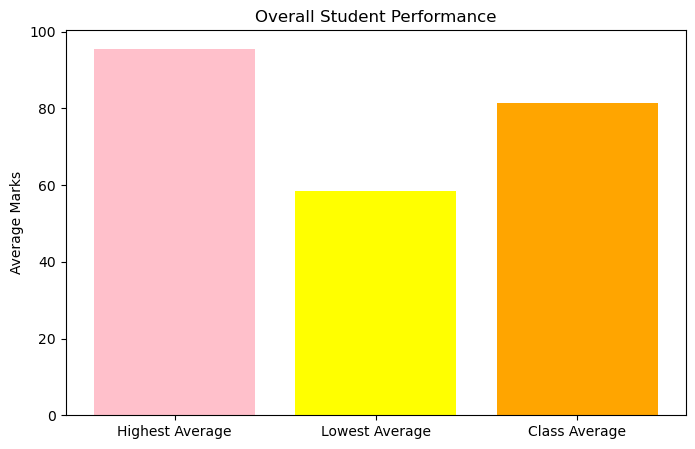

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Highest Average", "Lowest Average", "Class Average"],
    [highest, lowest, overall_average],
    color=['pink','yellow','orange']
)

plt.title("Overall Student Performance")
plt.ylabel("Average Marks")

plt.show()

#### Subject-wise Performance Analysis

In [15]:
for Subject in Subjects:
    print("\nSubject:", Subject)
    print("Average:", round(df[Subject].mean(), 2))
    print("Highest:", df[Subject].max())
    print("Lowest:", df[Subject].min())


Subject: Maths_Marks
Average: 79.4
Highest: 97
Lowest: 54

Subject: Science_Marks
Average: 80.95
Highest: 96
Lowest: 60

Subject: English_Marks
Average: 81.95
Highest: 98
Lowest: 57

Subject: Social_Studies_Marks
Average: 83.2
Highest: 96
Lowest: 63

Subject: Computer_Marks
Average: 81.9
Highest: 96
Lowest: 59


#### Showing Subject-wise Performance Analysis

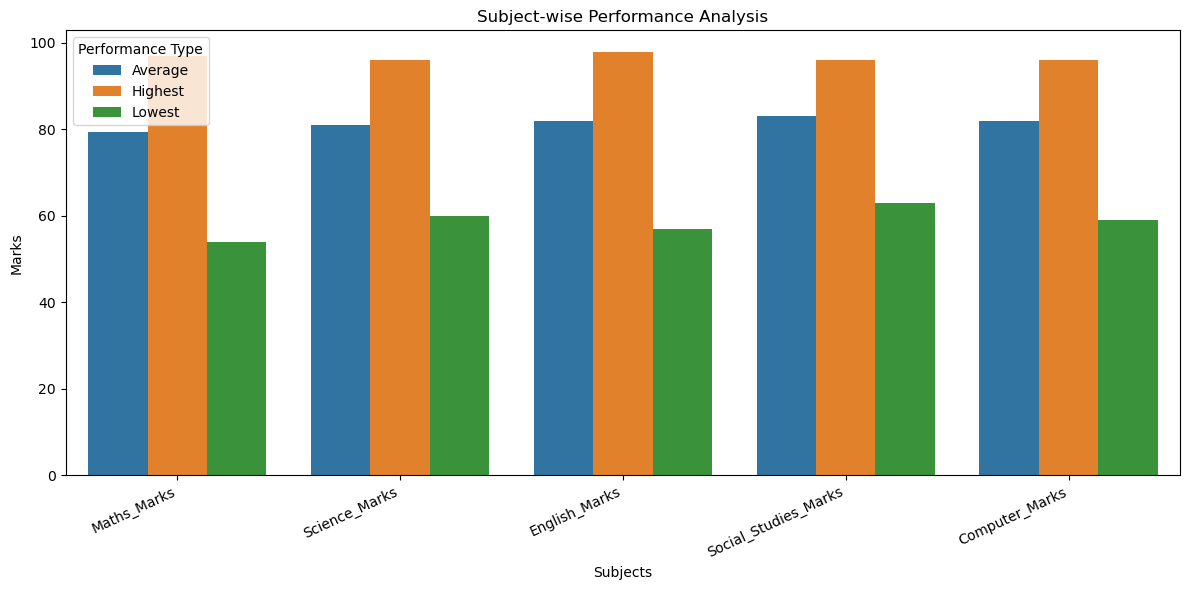

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = []

for Subject in Subjects:
    data.append({
        "Subject": Subject,
        "Performance Type": "Average",
        "Marks": df[Subject].mean()
    })
    data.append({
        "Subject": Subject,
        "Performance Type": "Highest",
        "Marks": df[Subject].max()
    })
    data.append({
        "Subject": Subject,
        "Performance Type": "Lowest",
        "Marks": df[Subject].min()
    })

subject_stats = pd.DataFrame(data)

# Create grouped bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=subject_stats,
    x="Subject",
    y="Marks",
    hue="Performance Type"
)

plt.title("Subject-wise Performance Analysis")
plt.xlabel("Subjects")
plt.ylabel("Marks")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Performance Type")
plt.tight_layout()
plt.show()

#### Top Scorers

In [17]:
top_students = df.sort_values(
    by="Average_Marks",
    ascending=False
).head(5)

print(top_students[["Student_ID", "Student_Name", "Average_Marks", "Grade"]])

   Student_ID   Student_Name  Average_Marks Grade
13    STU1014    Diya Kapoor           95.6     A
5     STU1006    Sneha Patel           94.4     A
9     STU1010     Kavya Nair           93.2     A
17    STU1018  Saanvi Bansal           93.2     A
1     STU1002    Priya Verma           91.6     A


#### Top 5 Performing Students

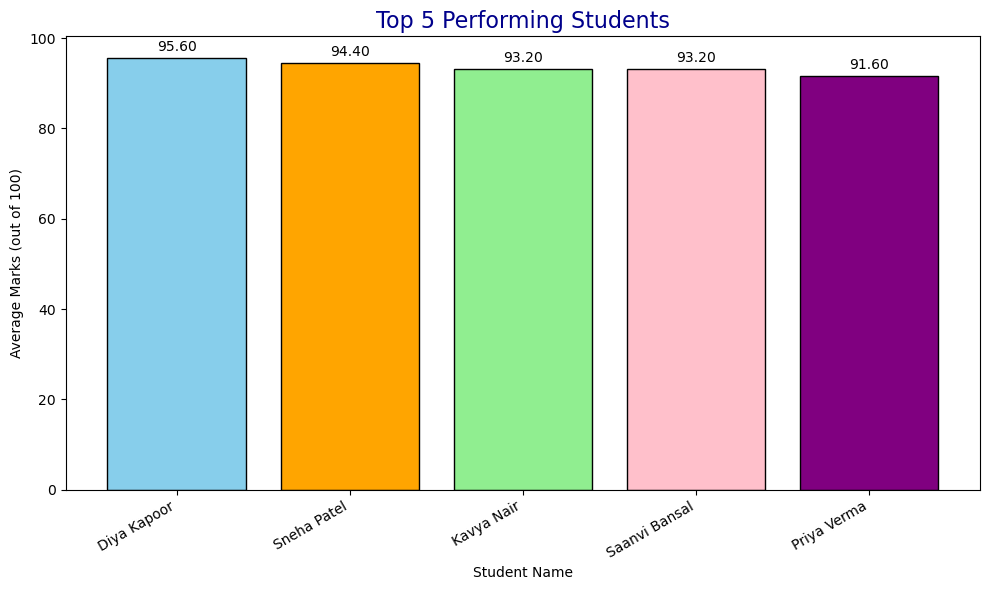

In [18]:
import matplotlib.pyplot as plt

top_students = df.sort_values(
    by="Average_Marks",
    ascending=False
).head(5)

plt.figure(figsize=(10, 6))

colors = ["skyblue", "orange", "lightgreen", "pink", "purple"]

bars = plt.bar(
    top_students["Student_Name"],
    top_students["Average_Marks"],
    color=colors,
    edgecolor="black"
)

plt.title("Top 5 Performing Students", fontsize=16, color="darkblue")
plt.xlabel("Student Name")
plt.ylabel("Average Marks (out of 100)")
plt.xticks(rotation=30, ha="right")

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

#### Showing the Result of Each Of Each Student 

In [19]:
for index, Student in df.iterrows():
    print("Student Name:", Student["Student_Name"])
    print("Total Marks:", Student["Total_Marks"])
    print("Average Marks:", round(Student["Average_Marks"], 2))
    print("Grade:", Student["Grade"])
    print("Result:", Student["Result"])
    print("---------------------------")

Student Name: Aarav Sharma
Total Marks: 424
Average Marks: 84.8
Grade: B
Result: Pass
---------------------------
Student Name: Priya Verma
Total Marks: 458
Average Marks: 91.6
Grade: A
Result: Pass
---------------------------
Student Name: Rohan Gupta
Total Marks: 352
Average Marks: 70.4
Grade: C
Result: Pass
---------------------------
Student Name: Ananya Singh
Total Marks: 451
Average Marks: 90.2
Grade: A
Result: Pass
---------------------------
Student Name: Kabir Mehta
Total Marks: 374
Average Marks: 74.8
Grade: C
Result: Pass
---------------------------
Student Name: Sneha Patel
Total Marks: 472
Average Marks: 94.4
Grade: A
Result: Pass
---------------------------
Student Name: Ishaan Kumar
Total Marks: 332
Average Marks: 66.4
Grade: C
Result: Pass
---------------------------
Student Name: Neha Yadav
Total Marks: 421
Average Marks: 84.2
Grade: B
Result: Pass
---------------------------
Student Name: Aditya Joshi
Total Marks: 394
Average Marks: 78.8
Grade: B
Result: Pass
--------